<a href="https://colab.research.google.com/github/saberBenhamda0/Deep_learning_-_Applications_assignments/blob/main/tp1/part2/predictive_maintenance_multiclass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Maintenance: Multiclass Classification with PyTorch
**Université Abdelmalek Essaadi — FST Tanger — Master MBD**  
Deep Learning lab · Professor ELAACHAK Lotfi

**Goal:** predict `Failure Type` from machine measurements. Run the cells from top to bottom in Google Colab. Download `predictive_maintenance.csv` from the [Kaggle dataset](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification) and upload it when prompted. A CPU runtime is sufficient, though the grid search may take several minutes.

The dataset is very imbalanced; accuracy alone can be misleading. We use macro F1 for selection and report per-class recall. The rare `Random Failures` class may be inherently difficult to predict and has few test examples, so its scores are unstable.

In [1]:
!pip -q install imbalanced-learn

In [2]:
import os, random, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from IPython.display import display
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
sns.set_theme(style='whitegrid')

## 1. Load and inspect the data

In [4]:
import kagglehub
from pathlib import Path

# Download the public Kaggle dataset and locate its CSV file.
dataset_dir = Path(kagglehub.dataset_download('shivamb/machine-predictive-maintenance-classification'))
csv_files = list(dataset_dir.rglob('predictive_maintenance.csv'))
if not csv_files:
    raise FileNotFoundError(f'predictive_maintenance.csv was not found in {dataset_dir}')
path = csv_files[0]
print('Dataset file:', path)

df = pd.read_csv(path)
df.columns = df.columns.str.strip()
print('Shape:', df.shape)
display(df.head())
df.info()
print('Missing values:'); display(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())

100%|██████████| 137k/137k [00:00<00:00, 330kB/s]

Extracting files...
Dataset file: /root/.cache/kagglehub/datasets/shivamb/machine-predictive-maintenance-classification/versions/1/predictive_maintenance.csv
Shape: (10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
Missing values:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0


Duplicate rows: 0


## 2. Cleaning and exploratory analysis
Remove exact duplicates and rows without the target. Identifiers (`UDI`, `Product ID`) are excluded because they identify records; `Target` is the binary failure label and would leak target information. Numeric missing values will be imputed and standardized; product type will be imputed and one-hot encoded **after splitting**, using training data only.

Class distribution:


,count
Failure Type,
No Failure,9652
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
Random Failures,18


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,L57163,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Target,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
Failure Type,10000,6,No Failure,9652,NaN,NaN,NaN,NaN,NaN,NaN,NaN


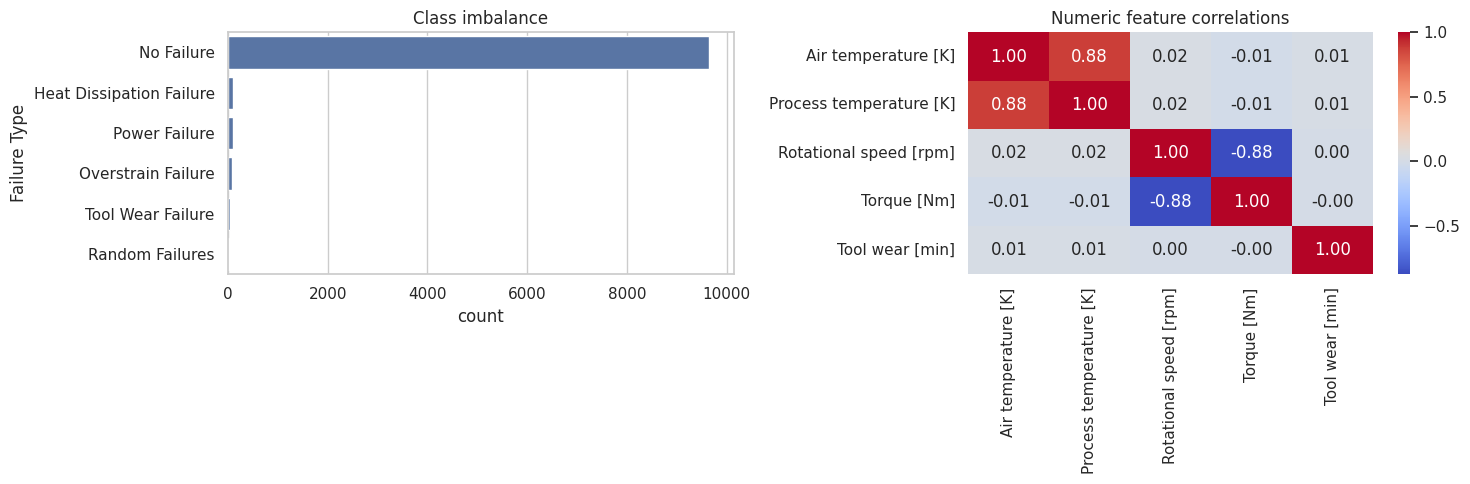

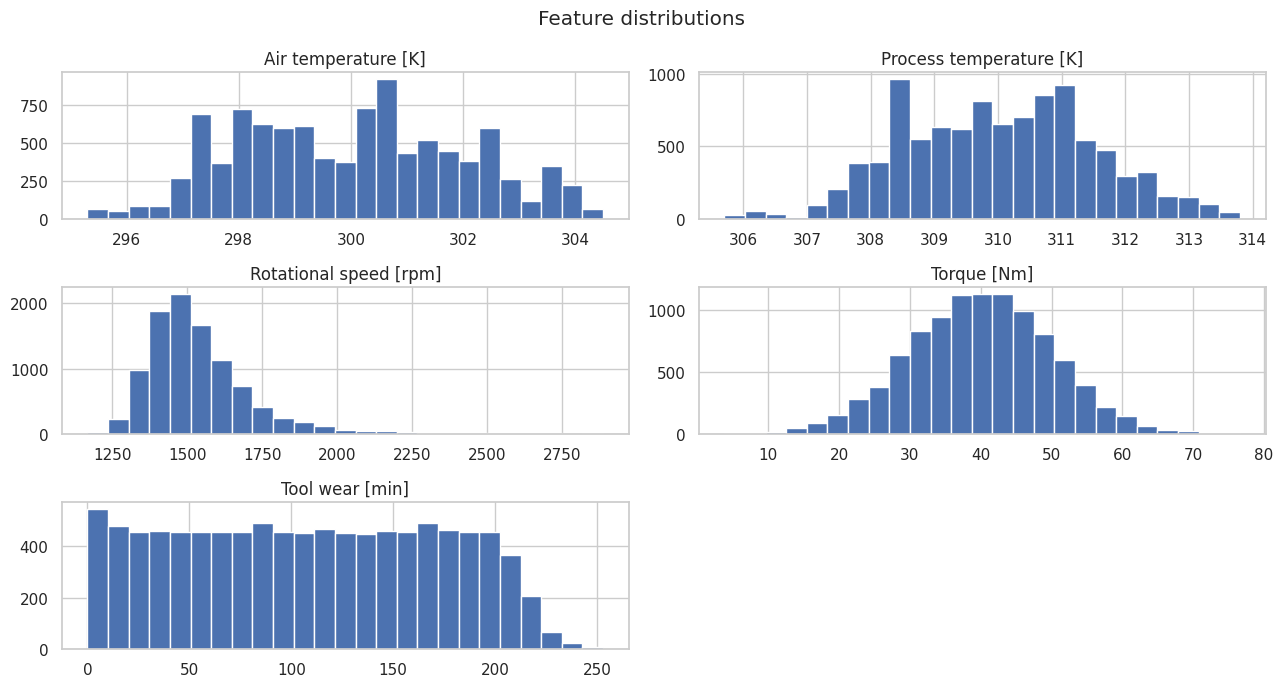

In [5]:
assert 'Failure Type' in df.columns, 'Expected the Kaggle predictive_maintenance.csv dataset.'
df = df.drop_duplicates().dropna(subset=['Failure Type']).copy()
df['Failure Type'] = df['Failure Type'].astype(str).str.strip()
print('Class distribution:'); display(df['Failure Type'].value_counts().to_frame('count'))
display(df.describe(include='all').T)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, y='Failure Type', order=df['Failure Type'].value_counts().index, ax=ax[0]); ax[0].set_title('Class imbalance')
num_cols = df.select_dtypes(include=np.number).columns.drop(['UDI','Target'], errors='ignore')
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax[1]); ax[1].set_title('Numeric feature correlations')
plt.tight_layout(); plt.show()
df[num_cols].hist(figsize=(13, 7), bins=25); plt.suptitle('Feature distributions'); plt.tight_layout(); plt.show()

In [6]:
drop_cols = ['Failure Type', 'Target', 'UDI', 'Product ID']
X = df.drop(columns=drop_cols, errors='ignore')
y_encoder = LabelEncoder(); y = y_encoder.fit_transform(df['Failure Type'])
print('Features:', list(X.columns)); print('Classes:', list(y_encoder.classes_))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=SEED, stratify=y)
# A validation split is used for regularization choices and learning curves.
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=.20, random_state=SEED, stratify=y_train)
print('Fit / validation / final test:', len(X_fit), len(X_val), len(X_test))
print('Test class counts:', dict(zip(*np.unique(y_test, return_counts=True))))
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
    ], sparse_threshold=0)

Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Classes: ['Heat Dissipation Failure', 'No Failure', 'Overstrain Failure', 'Power Failure', 'Random Failures', 'Tool Wear Failure']
Fit / validation / final test: 6400 1600 2000
Test class counts: {np.int64(0): np.int64(22), np.int64(1): np.int64(1930), np.int64(2): np.int64(16), np.int64(3): np.int64(19), np.int64(4): np.int64(4), np.int64(5): np.int64(9)}


## 3. Balance the training data
Random oversampling duplicates minority-class training examples. Unlike SMOTE, it does not interpolate one-hot categories. It is placed inside the cross-validation pipeline, so validation folds and the final test set retain their original distributions. Duplicate examples can increase overfitting; interpret rare-class metrics carefully.

In [7]:
print('Original fit classes:', dict(zip(*np.unique(y_fit, return_counts=True))))
_, y_demo = RandomOverSampler(random_state=SEED).fit_resample(X_fit, y_fit)
print('Balanced fit classes:', dict(zip(*np.unique(y_demo, return_counts=True))))

Original fit classes: {np.int64(0): np.int64(72), np.int64(1): np.int64(6178), np.int64(2): np.int64(49), np.int64(3): np.int64(61), np.int64(4): np.int64(11), np.int64(5): np.int64(29)}
Balanced fit classes: {np.int64(0): np.int64(6178), np.int64(1): np.int64(6178), np.int64(2): np.int64(6178), np.int64(3): np.int64(6178), np.int64(4): np.int64(6178), np.int64(5): np.int64(6178)}


## 4. PyTorch neural network and sklearn-compatible estimator
The model uses fully connected layers, ReLU and cross-entropy loss. The wrapper allows `GridSearchCV` to train a fresh PyTorch model in every fold. Loss and accuracy are recorded for the original (unbalanced) training and validation sets in the later experiments.

In [8]:
class TorchClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden=(64, 32), lr=.001, optimizer='adam', epochs=15, batch_size=128, dropout=0., weight_decay=0., early_stopping=False, patience=5, seed=42):
        self.hidden=hidden; self.lr=lr; self.optimizer=optimizer; self.epochs=epochs
        self.batch_size=batch_size; self.dropout=dropout; self.weight_decay=weight_decay
        self.early_stopping=early_stopping; self.patience=patience; self.seed=seed
    def fit(self, X, y, X_val=None, y_val=None, X_monitor=None, y_monitor=None):
        torch.manual_seed(self.seed); np.random.seed(self.seed)
        X=np.asarray(X, dtype=np.float32); y=np.asarray(y, dtype=np.int64)
        self.classes_=np.unique(y); self.n_features_in_=X.shape[1]
        layers=[]; d=X.shape[1]
        for width in self.hidden:
            layers.extend([nn.Linear(d,width), nn.ReLU()])
            if self.dropout: layers.append(nn.Dropout(self.dropout))
            d=width
        layers.append(nn.Linear(d, len(self.classes_))); self.model_=nn.Sequential(*layers)
        opt_cls = {'adam': torch.optim.Adam, 'sgd': torch.optim.SGD}[self.optimizer]
        opt=opt_cls(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn=nn.CrossEntropyLoss()
        loader=DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y)), batch_size=self.batch_size, shuffle=True, generator=torch.Generator().manual_seed(self.seed))
        self.history_=[]; best=float('inf'); best_state=None; bad=0
        def evaluate(a,b):
            self.model_.eval()
            with torch.no_grad():
                logits=self.model_(torch.tensor(np.asarray(a,dtype=np.float32)))
                loss=loss_fn(logits,torch.tensor(np.asarray(b,dtype=np.int64))).item()
                acc=(logits.argmax(1).numpy()==np.asarray(b)).mean()
            return loss,acc
        for epoch in range(self.epochs):
            self.model_.train()
            for xb,yb in loader:
                opt.zero_grad(); loss=loss_fn(self.model_(xb),yb); loss.backward(); opt.step()
            row={'epoch':epoch+1}
            row['train_loss'],row['train_acc']=evaluate(X_monitor if X_monitor is not None else X, y_monitor if y_monitor is not None else y)
            if X_val is not None:
                row['val_loss'],row['val_acc']=evaluate(X_val,y_val)
                if row['val_loss'] < best - 1e-4:
                    best=row['val_loss']; best_state=copy.deepcopy(self.model_.state_dict()); bad=0
                else: bad+=1
            self.history_.append(row)
            if self.early_stopping and X_val is not None and bad>=self.patience: break
        if self.early_stopping and best_state is not None: self.model_.load_state_dict(best_state)
        return self
    def predict(self, X):
        self.model_.eval()
        with torch.no_grad(): return self.model_(torch.tensor(np.asarray(X,dtype=np.float32))).argmax(1).numpy()
    def predict_proba(self, X):
        self.model_.eval()
        with torch.no_grad(): return torch.softmax(self.model_(torch.tensor(np.asarray(X,dtype=np.float32))),dim=1).numpy()

## 5. Hyperparameter tuning with GridSearchCV
Three stratified folds compare learning rate, optimizer, epochs, and network architecture using macro F1. Preprocessing and oversampling are fitted separately in each training fold. This modest grid contains 24 configurations; you may extend it, but it will take longer.

In [13]:
import time
from sklearn.model_selection import ParameterGrid

pipe = ImbPipeline([
    ('prep', make_preprocessor()),
    ('balance', RandomOverSampler(random_state=SEED)),
    ('model', TorchClassifier(batch_size=1024))
])

param_grid = {
    'model__hidden': [(64, 32), (128, 64)],
    'model__lr': [0.001, 0.01],
    'model__optimizer': ['adam', 'sgd'],
    'model__epochs': [10, 20]
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED)

print(
    f"Running {len(ParameterGrid(param_grid))} configurations "
    f"x {cv.get_n_splits()} folds = "
    f"{len(ParameterGrid(param_grid)) * cv.get_n_splits()} fits.",
    flush=True
)

search = GridSearchCV(
    pipe,
    param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=3,
    error_score='raise'
)

start = time.time()
search.fit(X_fit, y_fit)

print(f"Finished in {(time.time() - start) / 60:.1f} minutes")
print('Best parameters:', search.best_params_)
print('Best cross-validation macro F1:', round(search.best_score_, 4))

results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(
    results[
        ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    ].head(10)
)

Running 16 configurations x 2 folds = 32 fits.
Fitting 2 folds for each of 16 candidates, totalling 32 fits
[CV 1/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.001, model__optimizer=adam;, score=0.309 total time=  15.7s
[CV 2/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.001, model__optimizer=adam;, score=0.304 total time=   7.8s
[CV 1/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.001, model__optimizer=sgd;, score=0.169 total time=   5.5s
[CV 2/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.001, model__optimizer=sgd;, score=0.152 total time=   2.9s
[CV 1/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.01, model__optimizer=adam;, score=0.499 total time=   3.3s
[CV 2/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.01, model__optimizer=adam;, score=0.464 total time=   5.1s
[CV 1/2] END model__epochs=10, model__hidden=(64, 32), model__lr=0.01, model__optimizer=sgd;, score=0.182 total time=   3.4s
[CV 2/2] 

,params,mean_test_score,std_test_score,rank_test_score
14,"{'model__epochs': 20, 'model__hidden': (128, 6...",0.549354,0.007301,1
10,"{'model__epochs': 20, 'model__hidden': (64, 32...",0.543052,0.014778,2
2,"{'model__epochs': 10, 'model__hidden': (64, 32...",0.481118,0.017394,3
6,"{'model__epochs': 10, 'model__hidden': (128, 6...",0.475770,0.041245,4
12,"{'model__epochs': 20, 'model__hidden': (128, 6...",0.445803,0.000320,5
8,"{'model__epochs': 20, 'model__hidden': (64, 32...",0.390852,0.005307,6
4,"{'model__epochs': 10, 'model__hidden': (128, 6...",0.374753,0.001299,7
0,"{'model__epochs': 10, 'model__hidden': (64, 32...",0.306478,0.002074,8
3,"{'model__epochs': 10, 'model__hidden': (64, 32...",0.187711,0.005341,9
9,"{'model__epochs': 20, 'model__hidden': (64, 32...",0.162057,0.008591,10


## 6–8. Regularization experiments and learning curves
Use the same fit/validation split and tuned hyperparameters for each experiment. Compare baseline, dropout, L2 weight decay, early stopping and a combined model on **validation macro F1**. Curves show original fit and validation data, not oversampled examples. The final test set is evaluated only once, after model selection; this avoids choosing a model based on test results.

,model,epochs_run,validation_accuracy,validation_macro_recall,validation_macro_f1
3,early_stopping,9,0.942500,0.637455,0.526203
4,combined,16,0.931250,0.695819,0.523137
2,l2,20,0.960000,0.616967,0.520566
0,baseline,20,0.959375,0.607566,0.504321
1,dropout,20,0.927500,0.656906,0.486268


Selected: early_stopping


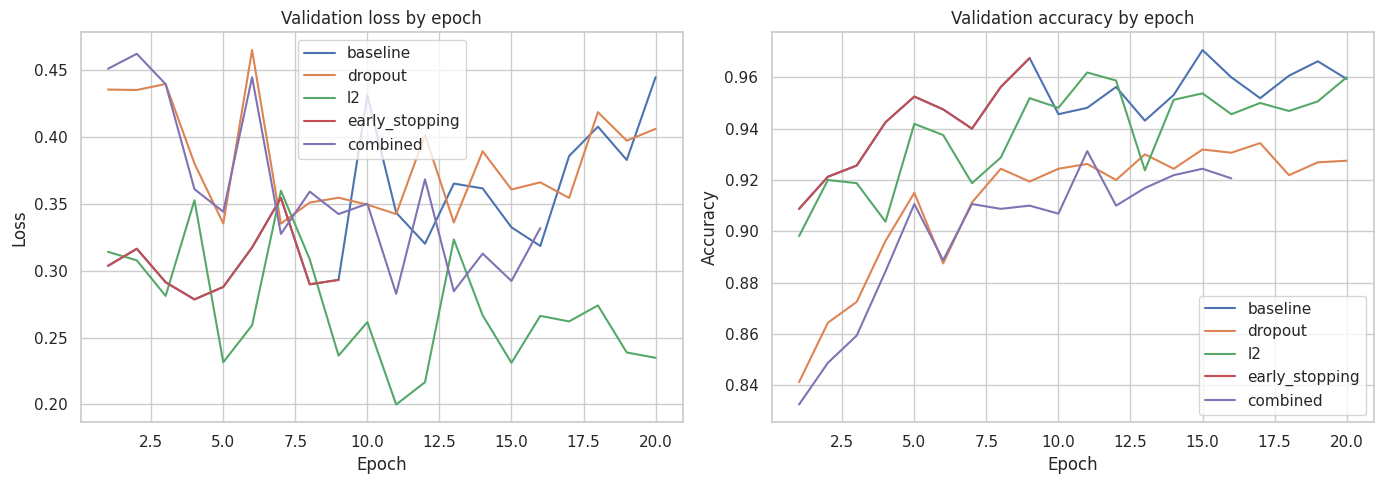

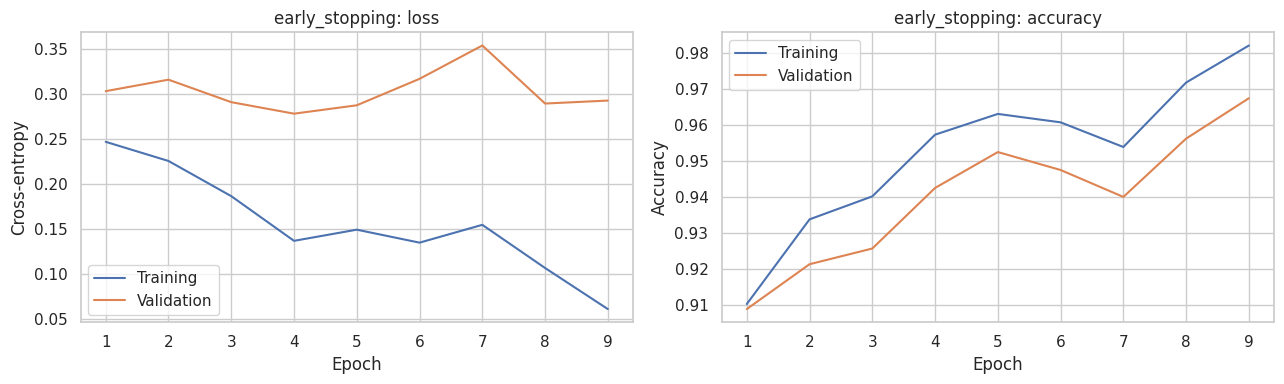

In [14]:
prep=make_preprocessor(); A=prep.fit_transform(X_fit); V=prep.transform(X_val)
A_bal,y_bal=RandomOverSampler(random_state=SEED).fit_resample(A,y_fit)
best={k.replace('model__',''):v for k,v in search.best_params_.items()}
variants={'baseline':{}, 'dropout':{'dropout':.2}, 'l2':{'weight_decay':1e-4}, 'early_stopping':{'early_stopping':True, 'patience':5}, 'combined':{'dropout':.2, 'weight_decay':1e-4, 'early_stopping':True, 'patience':5}}
models={}; rows=[]
for name, opts in variants.items():
    model=TorchClassifier(**best, **opts)
    model.fit(A_bal,y_bal,X_val=V,y_val=y_val,X_monitor=A,y_monitor=y_fit)
    models[name]=model; pred=model.predict(V)
    rows.append({'model':name,'epochs_run':len(model.history_),'validation_accuracy':accuracy_score(y_val,pred),'validation_macro_recall':recall_score(y_val,pred,average='macro',zero_division=0),'validation_macro_f1':f1_score(y_val,pred,average='macro',zero_division=0)})
comparison=pd.DataFrame(rows).sort_values('validation_macro_f1',ascending=False)
display(comparison)
selected=comparison.iloc[0]['model']; print('Selected:',selected)
fig, axes=plt.subplots(1,2,figsize=(14,5))
for name,model in models.items():
    h=pd.DataFrame(model.history_)
    axes[0].plot(h.epoch,h.val_loss,label=name); axes[1].plot(h.epoch,h.val_acc,label=name)
axes[0].set(title='Validation loss by epoch',xlabel='Epoch',ylabel='Loss'); axes[1].set(title='Validation accuracy by epoch',xlabel='Epoch',ylabel='Accuracy')
for a in axes: a.legend()
plt.tight_layout(); plt.show()
h=pd.DataFrame(models[selected].history_)
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(h.epoch,h.train_loss,label='Training'); ax[0].plot(h.epoch,h.val_loss,label='Validation'); ax[0].set(title=f'{selected}: loss',xlabel='Epoch',ylabel='Cross-entropy')
ax[1].plot(h.epoch,h.train_acc,label='Training'); ax[1].plot(h.epoch,h.val_acc,label='Validation'); ax[1].set(title=f'{selected}: accuracy',xlabel='Epoch',ylabel='Accuracy')
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### Interpret the curves
- If training loss decreases while validation loss rises, the model may be overfitting. Dropout, weight decay, or early stopping may help.
- If both losses remain high, the model may be underfitting or may need different hyperparameters.
- High accuracy can mostly reflect the dominant `No Failure` class. Compare macro F1 and per-class sensitivity as well. Write your own observations after running the notebook; the plots depend on the actual run.

## 9. Final evaluation on training and test sets
For an unbiased final evaluation, the selected model is kept as trained on the fit split. Training metrics below use the original fit examples, not the oversampled dataset. The test set was never used to fit the scaler, oversample, tune hyperparameters, or choose a regularization technique. Sensitivity is recall; macro recall averages sensitivity equally across classes.


Training (fit split): accuracy=0.9573 | macro sensitivity=0.9789 | macro F1=0.6684 | weighted F1=0.9683
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.81      0.92      0.86        72
              No Failure       1.00      0.96      0.98      6178
      Overstrain Failure       0.56      1.00      0.72        49
           Power Failure       0.66      1.00      0.80        61
         Random Failures       0.22      1.00      0.37        11
       Tool Wear Failure       0.17      1.00      0.29        29

                accuracy                           0.96      6400
               macro avg       0.57      0.98      0.67      6400
            weighted avg       0.99      0.96      0.97      6400


Test: accuracy=0.9475 | macro sensitivity=0.6114 | macro F1=0.5291 | weighted F1=0.9598
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.72      0.82      0.77        22
          

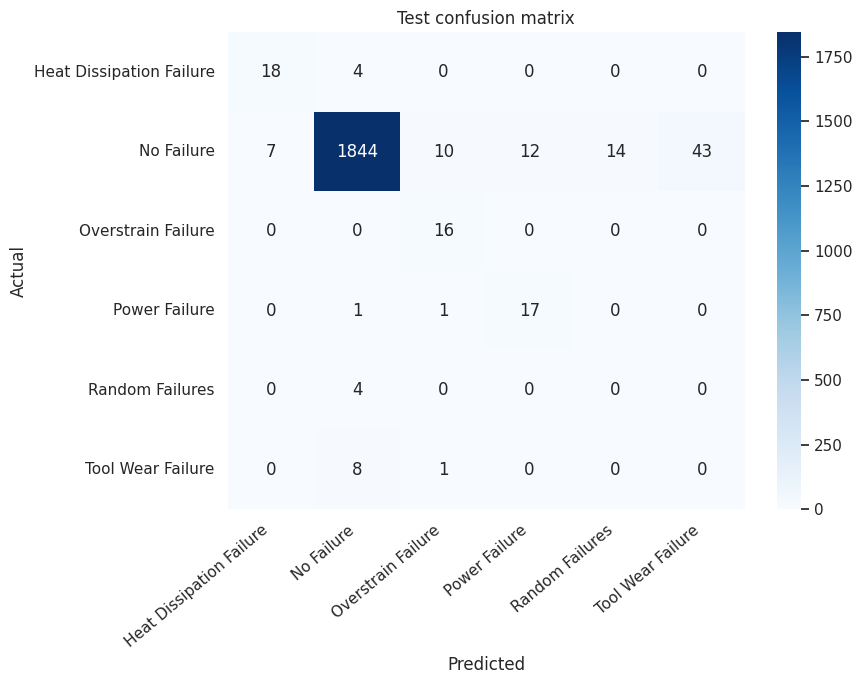

In [15]:
final_model=models[selected]; T=prep.transform(X_test)
labels=np.arange(len(y_encoder.classes_))
def report(split, features, truth):
    pred=final_model.predict(features)
    print(f"\n{split}: accuracy={accuracy_score(truth,pred):.4f} | macro sensitivity={recall_score(truth,pred,average='macro',zero_division=0):.4f} | macro F1={f1_score(truth,pred,average='macro',zero_division=0):.4f} | weighted F1={f1_score(truth,pred,average='weighted',zero_division=0):.4f}")
    print(classification_report(truth,pred,labels=labels,target_names=y_encoder.classes_,zero_division=0))
    return pred
train_pred=report('Training (fit split)',A,y_fit)
test_pred=report('Test',T,y_test)
cm=confusion_matrix(y_test,test_pred,labels=labels)
plt.figure(figsize=(9,7)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=y_encoder.classes_,yticklabels=y_encoder.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Test confusion matrix'); plt.xticks(rotation=40,ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

## 10. Brief synthesis
In this lab, I learned to clean and explore a predictive-maintenance dataset, split data before fitting preprocessing, and handle class imbalance by oversampling training data only. I built a multiclass neural network in PyTorch and used sklearn GridSearchCV to compare architectures, learning rates, optimizers and epochs. I compared dropout, L2 regularization and early stopping using validation data, then evaluated the chosen model with accuracy, macro sensitivity, F1 and a confusion matrix. The main limitation is that rare failure classes have few examples, so accuracy alone is not enough and per-class results can vary.